downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Components for 95% variance: 123
Max component diff vs sklearn: 2.496899333553459e-05


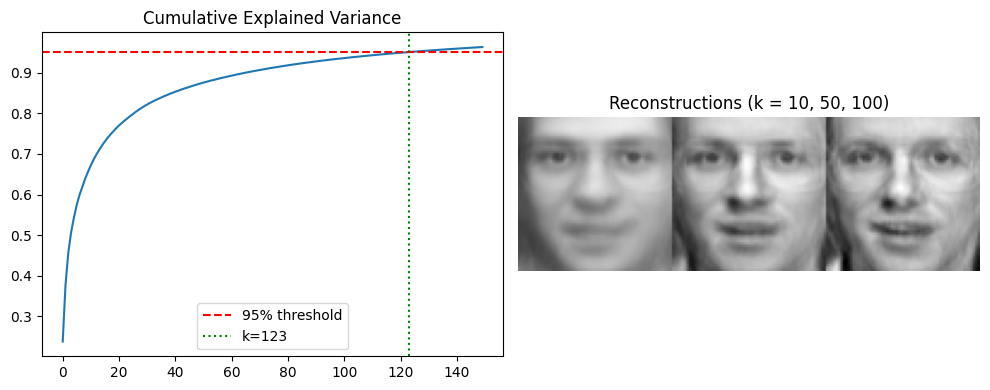

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA

faces = fetch_olivetti_faces(shuffle=True, random_state=42)
X = faces.data
mean = X.mean(axis=0)
X_c = X - mean

cov = np.cov(X_c, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov)
idx = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[idx], eigvecs[:, idx]

cum_var = np.cumsum(eigvals) / np.sum(eigvals)
n_95 = int(np.argmax(cum_var >= 0.95)) + 1
print("Components for 95% variance:", n_95)

sk_pca = PCA(n_components=n_95).fit(X)
print("Max component diff vs sklearn:", np.max(np.abs(sk_pca.explained_variance_ratio_ - (eigvals[:n_95] / np.sum(eigvals)))))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(cum_var[:150])
axes[0].axhline(0.95, color="r", linestyle="--", label="95% threshold")
axes[0].axvline(n_95, color="g", linestyle=":", label=f"k={n_95}")
axes[0].set_title("Cumulative Explained Variance"); axes[0].legend()

sample = X_c[0]
recons = [mean + sample @ eigvecs[:, :k] @ eigvecs[:, :k].T for k in [10, 50, 100]]
grid = np.hstack([r.reshape(64, 64) for r in recons])
axes[1].imshow(grid, cmap="gray")
axes[1].set_title("Reconstructions (k = 10, 50, 100)"); axes[1].axis("off")
plt.tight_layout(); plt.show()